<a href="https://colab.research.google.com/github/nandamanohar/ICT-intermediate-assessment-and-case-study/blob/main/Unsupervised_CASESTUDY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
adult_data=pd.read_csv('/content/adult_dataset.csv')
adult_data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [3]:
adult_data.shape

(48842, 15)

In [4]:
adult_data.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')

Data Preprocessing

In [5]:
adult_data.isna().sum()

,0
age,2442
workclass,3362
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,3357
relationship,0
race,0
sex,0


In [6]:
adult_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


numerical with mean/median and categorical with mode

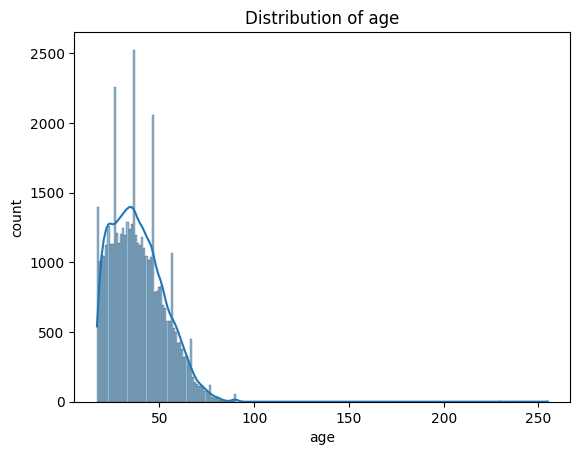

In [7]:
sns.histplot(adult_data['age'],kde = True)
plt.xlabel('age')
plt.ylabel('count')
plt.title('Distribution of age')
plt.show()

In [8]:
adult_data['age'].median()

37.0

In [9]:
adult_data['age']=adult_data['age'].fillna(adult_data['age'].median())

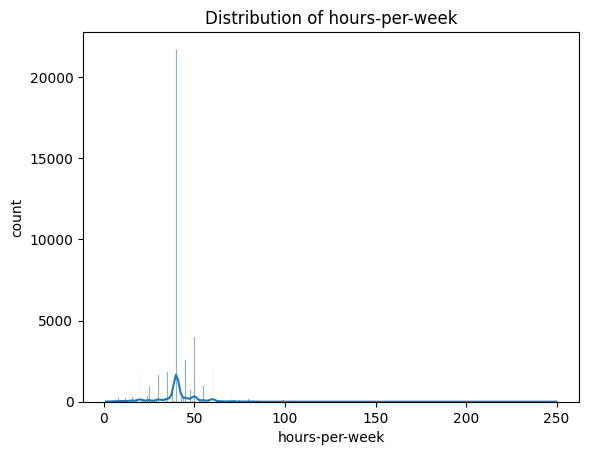

In [10]:
sns.histplot(adult_data['hours-per-week'],kde = True)
plt.xlabel('hours-per-week')
plt.ylabel('count')
plt.title('Distribution of hours-per-week')
plt.show()

In [11]:
adult_data['hours-per-week'].median()

40.0

In [12]:
adult_data['hours-per-week']=adult_data['hours-per-week'].fillna(adult_data['hours-per-week'].median())

In [13]:
adult_data['workclass'].unique()

array(['State-gov', 'Self-emp-not-inc', 'Private', 'Federal-gov', nan,
       'Local-gov', '?', 'Self-emp-inc', 'Without-pay', 'Never-worked'],
      dtype=object)

In [14]:
adult_data['workclass']=adult_data['workclass'].replace('?', np.nan)

In [15]:
adult_data['workclass']=adult_data['workclass'].fillna(adult_data['workclass'].mode()[0])

In [16]:
adult_data['workclass'].value_counts()

,count
workclass,
Private,37345
Self-emp-not-inc,3649
Local-gov,2973
State-gov,1877
Self-emp-inc,1625
Federal-gov,1346
Without-pay,18
Never-worked,9


In [17]:
adult_data['occupation'].unique()

array(['Adm-clerical', 'Exec-managerial', 'Handlers-cleaners',
       'Prof-specialty', 'Other-service', 'Sales', 'Craft-repair',
       'Transport-moving', 'Farming-fishing', 'Machine-op-inspct',
       'Tech-support', nan, 'Protective-serv', '?', 'Armed-Forces',
       'Priv-house-serv'], dtype=object)

In [18]:
adult_data['occupation']=adult_data['occupation'].replace('?', np.nan)

In [19]:
adult_data['occupation']=adult_data['occupation'].fillna(adult_data['occupation'].mode()[0])

In [20]:
adult_data['occupation'].value_counts()

,count
occupation,
Prof-specialty,10969
Craft-repair,5791
Exec-managerial,5771
Adm-clerical,5329
Sales,5231
Other-service,4657
Machine-op-inspct,2874
Transport-moving,2238
Handlers-cleaners,1977


In [21]:
adult_data['native-country'].unique()

array([nan, 'United-States', 'Cuba', 'Jamaica', 'India', '?', 'Mexico',
       'South', 'Puerto-Rico', 'Honduras', 'England', 'Germany', 'Iran',
       'Philippines', 'Italy', 'Columbia', 'Cambodia', 'Thailand',
       'Canada', 'Ecuador', 'Laos', 'Taiwan', 'Haiti', 'Portugal',
       'Dominican-Republic', 'El-Salvador', 'Poland', 'France',
       'Guatemala', 'China', 'Japan', 'Yugoslavia', 'Peru',
       'Outlying-US(Guam-USVI-etc)', 'Scotland', 'Trinadad&Tobago',
       'Greece', 'Nicaragua', 'Vietnam', 'Hong', 'Ireland', 'Hungary',
       'Holand-Netherlands'], dtype=object)

In [22]:
adult_data['native-country']=adult_data['native-country'].replace('?', np.nan)

In [23]:
adult_data['native-country']=adult_data['native-country'].fillna(adult_data['native-country'].mode()[0])

In [24]:
adult_data['native-country'].value_counts()

,count
native-country,
United-States,44882
Mexico,908
Philippines,282
Germany,194
Puerto-Rico,175
Canada,170
El-Salvador,147
India,143
Cuba,132


In [25]:
adult_data['income'].unique()

array(['<=50K', '>50K', '<=50K.', '>50K.'], dtype=object)

In [26]:
adult_data['income'] = adult_data['income'].replace('<=50K.', '<=50K')

In [27]:
adult_data['income'] = adult_data['income'].replace('>50K.', '>50K')

In [28]:
adult_data['income'].unique()

array(['<=50K', '>50K'], dtype=object)

In [29]:
adult_data.isna().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


Outliers

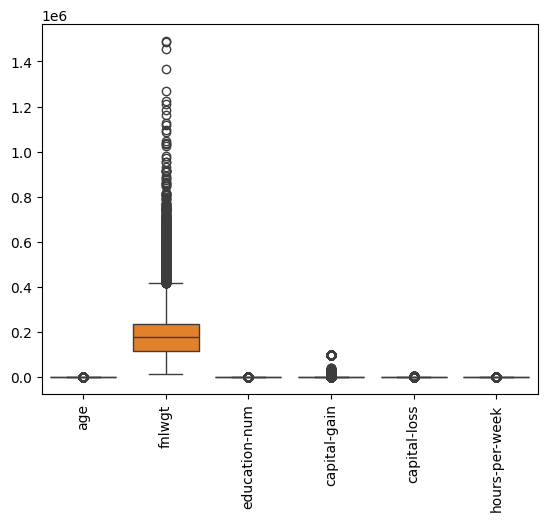

In [30]:
sns.boxplot(adult_data)
plt.xticks(rotation=90)
plt.show()

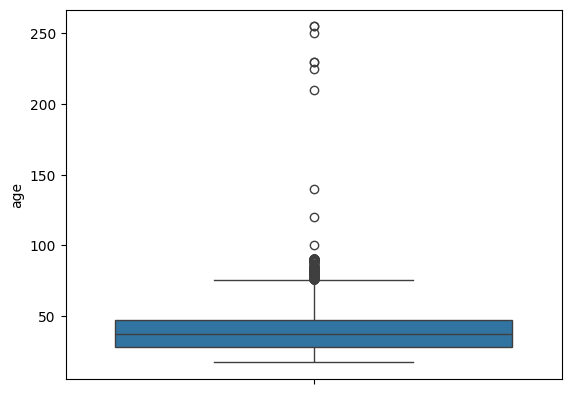

In [31]:
sns.boxplot(adult_data['age'])
plt.xticks(rotation=90)
plt.show()

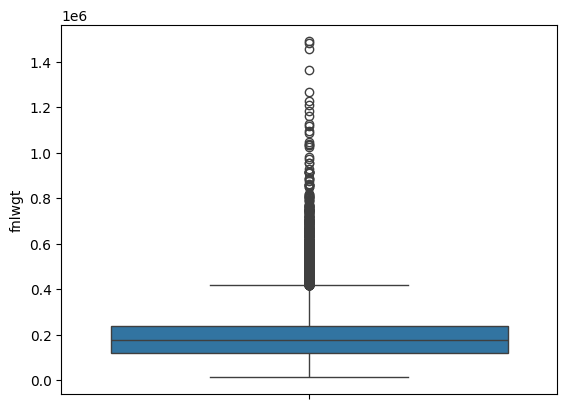

In [32]:
sns.boxplot(adult_data['fnlwgt'])
plt.xticks(rotation=90)
plt.show()

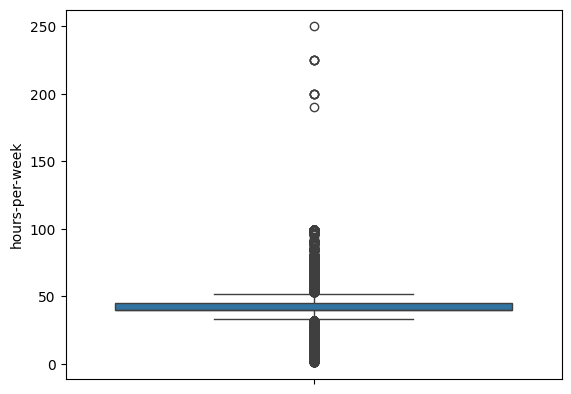

In [33]:
sns.boxplot(adult_data['hours-per-week'])
plt.xticks(rotation=90)
plt.show()

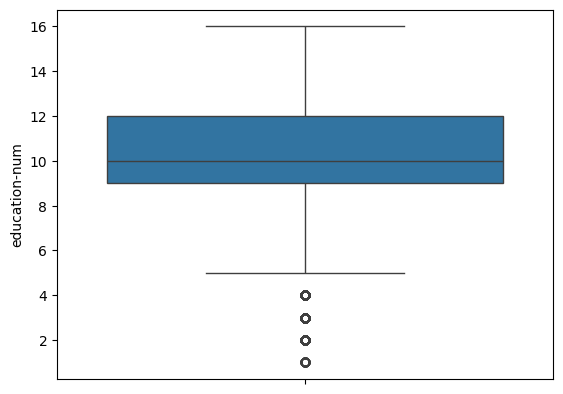

In [34]:
sns.boxplot(adult_data['education-num'])
plt.xticks(rotation=90)
plt.show()

In [35]:
Q1_age = adult_data['age'].quantile(0.25)
Q3_age = adult_data['age'].quantile(0.75)
IQR_age = Q3_age - Q1_age

lr_bound_age = Q1_age - 1.5 * IQR_age
ur_bound_age = Q3_age + 1.5 * IQR_age

In [36]:
Q1_min_hours_week = adult_data['hours-per-week'].quantile(0.25)
Q3_min_hours_week = adult_data['hours-per-week'].quantile(0.75)
IQR_min_hours_week = Q3_min_hours_week - Q1_min_hours_week

lr_bound_min_hours_week = Q1_min_hours_week - 1.5 * IQR_min_hours_week
ur_bound_min_hours_week = Q3_min_hours_week + 1.5 * IQR_min_hours_week

In [37]:
Q1_min_edu_num = adult_data['education-num'].quantile(0.25)
Q3_min_edu_num = adult_data['education-num'].quantile(0.75)
IQR_min_edu_num = Q3_min_edu_num - Q1_min_edu_num

lr_bound_min_edu_num = Q1_min_edu_num - 1.5 * IQR_min_edu_num
ur_bound_min_edu_num = Q3_min_edu_num + 1.5 * IQR_min_edu_num

In [38]:
Q1_min_fnlwgt = adult_data['fnlwgt'].quantile(0.25)
Q3_min_fnlwgt = adult_data['fnlwgt'].quantile(0.75)
IQR_min_fnlwgt = Q3_min_fnlwgt - Q1_min_fnlwgt

lr_bound_min_fnlwgt = Q1_min_fnlwgt - 1.5 * IQR_min_fnlwgt
ur_bound_min_fnlwgt = Q3_min_fnlwgt + 1.5 * IQR_min_fnlwgt


In [39]:
adult_data = adult_data[
    (adult_data['age'] > lr_bound_age) & (adult_data['age'] < ur_bound_age) &
    (adult_data['hours-per-week'] > lr_bound_min_hours_week) & (adult_data['hours-per-week'] < ur_bound_min_hours_week) &
    (adult_data['education-num'] > lr_bound_min_edu_num) & (adult_data['education-num'] < ur_bound_min_edu_num) &
    (adult_data['fnlwgt'] > lr_bound_min_fnlwgt) & (adult_data['fnlwgt'] < ur_bound_min_fnlwgt)
]

In [40]:
adult_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 33567 entries, 0 to 48840
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             33567 non-null  float64
 1   workclass       33567 non-null  object 
 2   fnlwgt          33567 non-null  int64  
 3   education       33567 non-null  object 
 4   education-num   33567 non-null  int64  
 5   marital-status  33567 non-null  object 
 6   occupation      33567 non-null  object 
 7   relationship    33567 non-null  object 
 8   race            33567 non-null  object 
 9   sex             33567 non-null  object 
 10  capital-gain    33567 non-null  int64  
 11  capital-loss    33567 non-null  int64  
 12  hours-per-week  33567 non-null  float64
 13  native-country  33567 non-null  object 
 14  income          33567 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 4.1+ MB


In [41]:
adult_data.select_dtypes(include=['object'])

,workclass,education,marital-status,occupation,relationship,race,sex,native-country,income
0,State-gov,Bachelors,Never-married,Adm-clerical,Not-in-family,White,Male,United-States,<=50K
2,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,United-States,<=50K
3,Private,11th,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,United-States,<=50K
4,Private,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Black,Female,Cuba,<=50K
5,Private,Masters,Married-civ-spouse,Exec-managerial,Wife,White,Female,United-States,<=50K
...,...,...,...,...,...,...,...,...,...
48836,Private,Bachelors,Never-married,Prof-specialty,Own-child,White,Male,United-States,<=50K
48837,Private,Bachelors,Divorced,Prof-specialty,Not-in-family,White,Female,United-States,<=50K
48838,Private,HS-grad,Widowed,Prof-specialty,Other-relative,Black,Male,United-States,<=50K
48839,Private,Bachelors,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K


In [42]:
adult_data['workclass'].unique()

array(['State-gov', 'Private', 'Self-emp-not-inc', 'Federal-gov',
       'Local-gov', 'Self-emp-inc', 'Never-worked', 'Without-pay'],
      dtype=object)

In [43]:
adult_data['education'].unique()

array(['Bachelors', 'HS-grad', '11th', 'Masters', 'Assoc-acdm',
       'Assoc-voc', '9th', 'Some-college', 'Doctorate', 'Prof-school',
       '10th', '12th'], dtype=object)

In [44]:
adult_data['marital-status'].unique()

array(['Never-married', 'Divorced', 'Married-civ-spouse', 'Separated',
       'Widowed', 'Married-spouse-absent', 'Married-AF-spouse'],
      dtype=object)

In [45]:
adult_data['occupation'].unique()

array(['Adm-clerical', 'Handlers-cleaners', 'Prof-specialty',
       'Exec-managerial', 'Sales', 'Craft-repair', 'Farming-fishing',
       'Machine-op-inspct', 'Transport-moving', 'Tech-support',
       'Protective-serv', 'Other-service', 'Armed-Forces',
       'Priv-house-serv'], dtype=object)

In [46]:
adult_data['relationship'].unique()

array(['Not-in-family', 'Husband', 'Wife', 'Own-child', 'Unmarried',
       'Other-relative'], dtype=object)

In [47]:
adult_data['race'].unique()

array(['White', 'Black', 'Asian-Pac-Islander', 'Other',
       'Amer-Indian-Eskimo'], dtype=object)

In [48]:
adult_data['sex'].unique()

array(['Male', 'Female'], dtype=object)

In [49]:
adult_data['native-country'].unique()

array(['United-States', 'Cuba', 'India', 'Puerto-Rico', 'Mexico',
       'England', 'Germany', 'Iran', 'Philippines', 'Italy', 'Cambodia',
       'Laos', 'Taiwan', 'Portugal', 'Poland', 'France', 'Canada',
       'El-Salvador', 'South', 'Dominican-Republic', 'Jamaica', 'Haiti',
       'China', 'Japan', 'Yugoslavia', 'Peru',
       'Outlying-US(Guam-USVI-etc)', 'Scotland', 'Trinadad&Tobago',
       'Greece', 'Nicaragua', 'Vietnam', 'Guatemala', 'Hong', 'Columbia',
       'Ireland', 'Ecuador', 'Honduras', 'Thailand', 'Hungary',
       'Holand-Netherlands'], dtype=object)

In [50]:
adult_data['income'].unique()

array(['<=50K', '>50K'], dtype=object)

Encoding

In [51]:
num_cols=adult_data.select_dtypes(include=['int','float']).columns
num_cols

Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')

In [52]:
cat_cols=adult_data.select_dtypes(include=['object']).columns
cat_cols

Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country', 'income'],
      dtype='object')

In [53]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
adult_data['income'] = le.fit_transform(adult_data['income'])

In [54]:
adult_data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,United-States,0
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,0
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,0
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,0
5,37.0,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40.0,United-States,0


In [56]:
df1=adult_data.copy

In [57]:
adult_data = pd.get_dummies(adult_data, dtype = int, drop_first= True)

In [58]:
adult_data.head()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,income,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39.0,77516,13,2174,0,40.0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,38.0,215646,9,0,0,40.0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
3,53.0,234721,7,0,0,40.0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
4,28.0,338409,13,0,0,40.0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
5,37.0,284582,14,0,0,40.0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0


In [59]:
x=adult_data.drop('income', axis=1)

# K Means Clustering

In [60]:
#  using elbow method to find the optimum number of clusters
from sklearn.cluster import KMeans

wcss = []
for i in range(3,9):
  kmeans =KMeans(n_clusters=i, init= 'k-means++', random_state=42)
  kmeans.fit(x)
  wcss.append(kmeans.inertia_)

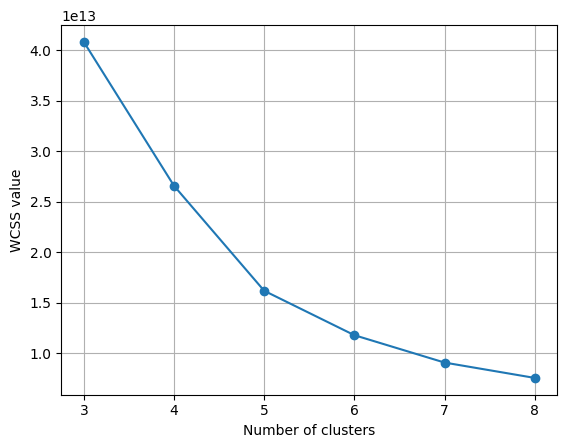

In [61]:
plt.plot(range(3,9),wcss,'o-')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS value')
plt.grid()

In [62]:
# elbow is appearing at k=4
# we can create kmeans model with no. of clusters=4

kmeans1 = KMeans(n_clusters=4, init='k-means++', random_state=42)
y_kmeans = kmeans1.fit_predict(x)

In [63]:
print(y_kmeans)

[2 3 3 ... 1 1 2]


In [64]:
#silhoutte score for kmean clustering

from sklearn.metrics import silhouette_score
sil_kmeans =  silhouette_score(x,y_kmeans)
print(sil_kmeans)

0.526760022943333


In [65]:
x_sample = x.sample(n=10000, random_state=42).copy()

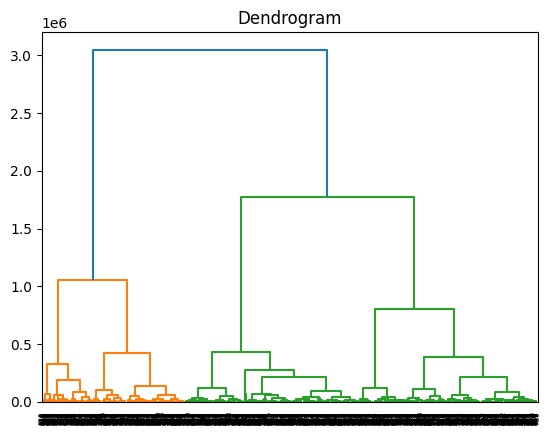

In [68]:
# using dendrogram to find the optimum number of clusters with a smaller sample size to prevent timeouts
import scipy.cluster.hierarchy as sch

# Downsample to 1000 records for efficient hierarchical linkage computation
x_small_sample = x_sample.sample(n=1000, random_state=42)

dendrogram = sch.dendrogram(sch.linkage(x_small_sample, method='ward'))
plt.title('Dendrogram')
plt.show()

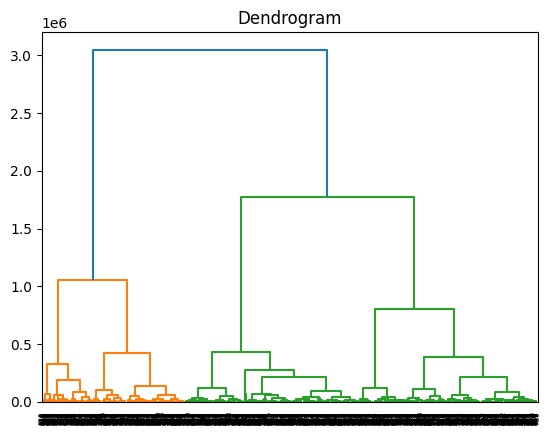

In [70]:
# using dentrogram to find the optimum number of clusters
import scipy.cluster.hierarchy as sch

dentrogram = sch.dendrogram(sch.linkage(x_small_sample,method='ward'))
plt.title('Dendrogram')
plt.show()

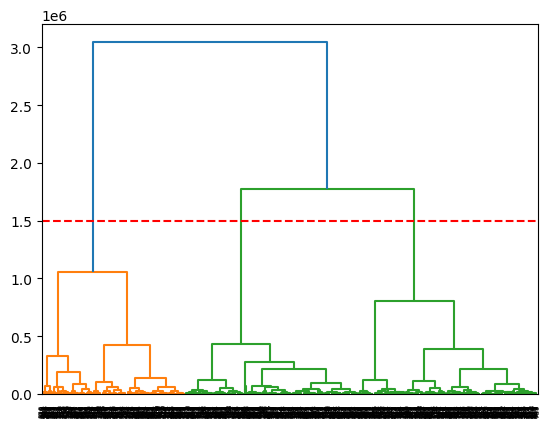

In [71]:
dentrogram = sch.dendrogram(sch.linkage(x_small_sample,method='ward'))
plt.axhline(y=1500000,color='red',linestyle='--')

In [74]:
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters=2, linkage = 'ward')
y_hc = hc.fit_predict(x_small_sample)

In [75]:
silhoutte_avg =  silhouette_score(x_small_sample,y_hc)
print(silhoutte_avg )

0.5398278998466384
